# E-commerce Cart Abandonment: Master ML Pipeline
Toàn bộ quy trình từ Khám phá dữ liệu (EDA), Trích xuất đặc trưng (Feature Engineering), Huấn luyện (Training) đến Đánh giá chuyên sâu (Evaluation) được gom vào một Notebook duy nhất.

## 1. Khám phá Dữ liệu (EDA) & Tính khả thi
Phân tích tỷ lệ bỏ giỏ hàng và chia tập Train/Val/Test chống rò rỉ dữ liệu.

In [1]:
import duckdb
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

db_path = "../../data/processed/ecommerce.duckdb"
con = duckdb.connect(db_path, read_only=True)

print("--- TARGET BALANCE (Sessions with Cart) ---")
df_balance = con.execute("""
SELECT COUNT(*) as total_cart_sessions, SUM(is_abandoned::INT) as abandoned_sessions, SUM(is_abandoned::INT)*100.0/COUNT(*) as abandon_rate_pct
FROM fct_session_funnel WHERE has_cart = TRUE AND first_event_date != '2019-11-15'
""").fetchdf()
display(df_balance)

print("\n--- TRAIN/VAL/TEST SPLITS ---")
df_split = con.execute("""
SELECT 
    CASE 
        WHEN first_event_date BETWEEN '2019-10-01' AND '2019-11-10' THEN '1_Train'
        WHEN first_event_date BETWEEN '2019-11-11' AND '2019-11-20' THEN '2_Val'
        WHEN first_event_date BETWEEN '2019-11-21' AND '2019-11-30' THEN '3_Test'
    END AS split,
    COUNT(*) as sessions, SUM(is_abandoned::INT)*100.0/COUNT(*) as abandon_rate_pct
FROM fct_session_funnel WHERE has_cart = TRUE AND first_event_date != '2019-11-15' GROUP BY 1 ORDER BY 1
""").fetchdf()
display(df_split)


--- TARGET BALANCE (Sessions with Cart) ---


,total_cart_sessions,abandoned_sessions,abandon_rate_pct
0,2060841,1120624.0,54.377024



--- TRAIN/VAL/TEST SPLITS ---


,split,sessions,abandon_rate_pct
0,1_Train,797130,49.600316
1,2_Val,822129,60.178755
2,3_Test,441582,52.198233


### Biểu đồ Trực quan hóa Dữ liệu (Visual EDA)
Hiển thị tỷ lệ mất mát giỏ hàng (Target Balance) và xu hướng rớt phễu theo thời gian thực.

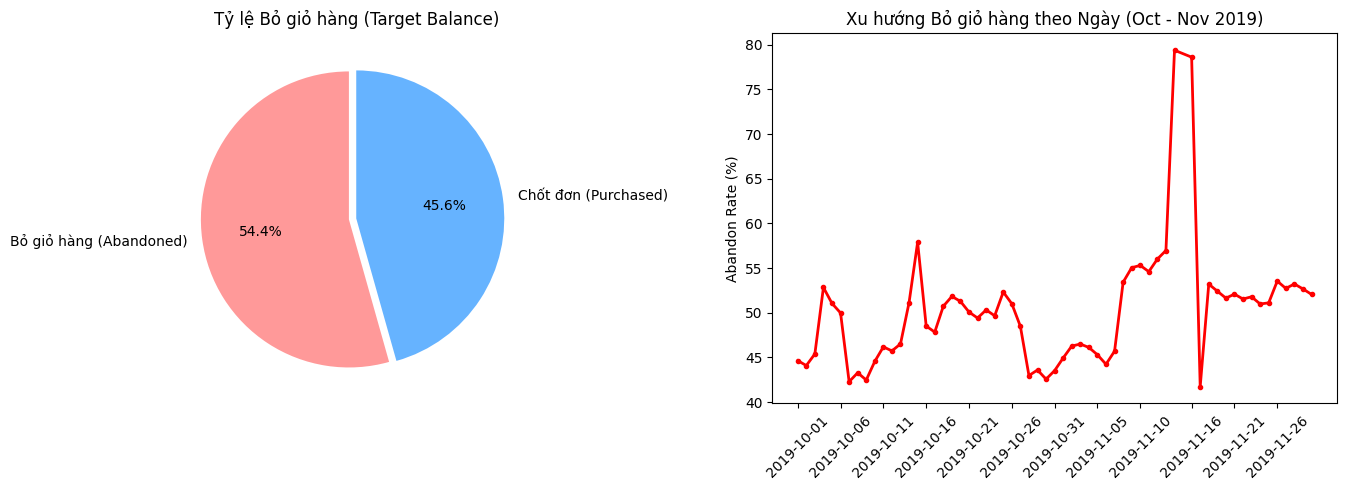

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Pie Chart: Target Balance
labels = ['Bỏ giỏ hàng (Abandoned)', 'Chốt đơn (Purchased)']
sizes = [df_balance['abandoned_sessions'][0], df_balance['total_cart_sessions'][0] - df_balance['abandoned_sessions'][0]]
axes[0].pie(sizes, labels=labels, autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], startangle=90, explode=(0.05, 0))
axes[0].set_title('Tỷ lệ Bỏ giỏ hàng (Target Balance)')

# 2. Line Chart: Daily Abandon Rate
df_trend = con.execute("""
SELECT first_event_date, SUM(is_abandoned::INT)*100.0/COUNT(*) as abandon_rate
FROM fct_session_funnel WHERE has_cart = TRUE AND first_event_date != '2019-11-15'
GROUP BY 1 ORDER BY 1
""").fetchdf()

axes[1].plot(df_trend['first_event_date'], df_trend['abandon_rate'], marker='.', color='red', linewidth=2)
axes[1].set_title('Xu hướng Bỏ giỏ hàng theo Ngày (Oct - Nov 2019)')
axes[1].set_ylabel('Abandon Rate (%)')
axes[1].set_xticks(df_trend['first_event_date'][::5]) # Show every 5th day for clean x-axis
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## 2. Feature Engineering
Tính toán các đặc trưng (Behavioral, Temporal, Historical) và lưu thành file Parquet.

In [3]:

import os
os.makedirs("../data/features", exist_ok=True)
features_path = "../data/features/features_v1.parquet"

sql = f"""
COPY (
    WITH oct_history AS (
        SELECT user_id, SUM(has_purchase::INT) AS oct_purchase_count, SUM((has_cart AND NOT has_purchase)::INT) AS oct_abandon_count, MAX(session_end) AS last_oct_session
        FROM fct_session_funnel WHERE first_event_month = '2019-10-01' GROUP BY user_id
    ),
    ml_base AS (
        SELECT 
            f.user_session, f.is_abandoned::INT AS target,
            EXTRACT('hour' FROM f.session_start) AS hour_of_day,
            EXTRACT('isodow' FROM f.session_start) AS day_of_week,
            (f.first_event_date IN ('2019-11-14', '2019-11-16', '2019-11-17', '2019-11-29'))::INT AS is_bf_week,
            f.view_count, f.cart_count, f.cart_value,
            COALESCE(f.cart_value / NULLIF(f.cart_count, 0), 0) AS avg_item_price,
            CASE 
                WHEN (f.cart_value / NULLIF(f.cart_count, 0)) < 50 THEN '0-50'
                WHEN (f.cart_value / NULLIF(f.cart_count, 0)) < 200 THEN '50-200'
                WHEN (f.cart_value / NULLIF(f.cart_count, 0)) < 500 THEN '200-500'
                WHEN (f.cart_value / NULLIF(f.cart_count, 0)) < 1000 THEN '500-1000'
                ELSE '1000+'
            END AS price_tier_bucket,
            COALESCE(h.oct_purchase_count, 0) AS oct_purchase_count,
            COALESCE(h.oct_abandon_count, 0) AS oct_abandon_count,
            (h.user_id IS NOT NULL)::INT AS is_returning_user,
            EXTRACT('epoch' FROM (f.session_start - h.last_oct_session))/86400.0 AS days_since_last_oct,
            CASE 
                WHEN f.first_event_date BETWEEN '2019-10-01' AND '2019-11-10' THEN 'train'
                WHEN f.first_event_date BETWEEN '2019-11-11' AND '2019-11-20' THEN 'val'
                WHEN f.first_event_date BETWEEN '2019-11-21' AND '2019-11-30' THEN 'test'
            END AS split_group
        FROM fct_session_funnel f
        LEFT JOIN oct_history h ON f.user_id = h.user_id
        WHERE f.has_cart = TRUE AND f.first_event_date != '2019-11-15'
    )
    SELECT * FROM ml_base
) TO '{features_path}' (FORMAT PARQUET);
"""
print("Building features (this takes a few seconds)...")
con.execute(sql)
print(f"Features saved to {features_path}!")


Building features (this takes a few seconds)...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Features saved to ../data/features/features_v1.parquet!


## 3. Huấn luyện Mô hình & Tuning (XGBoost)
Load data từ Parquet, xử lý Null, Train mô hình XGBoost tốt nhất.

In [4]:

import xgboost as xgb
from sklearn.metrics import roc_auc_score
import pickle

print("Loading features...")
df = pd.read_parquet("../data/features/features_v1.parquet")
df['days_since_last_oct'] = df['days_since_last_oct'].fillna(-1)
df = pd.get_dummies(df, columns=['price_tier_bucket'], drop_first=True)

features = [c for c in df.columns if c not in ['user_session', 'target', 'split_group']]
X_train = df[df['split_group'] == 'train'][features]
y_train = df[df['split_group'] == 'train']['target']
X_val = df[df['split_group'] == 'val'][features]
y_val = df[df['split_group'] == 'val']['target']
X_test = df[df['split_group'] == 'test'][features]
y_test = df[df['split_group'] == 'test']['target']

print("Training Optimal XGBoost Model...")
best_params = {'max_depth': 7, 'learning_rate': 0.1, 'n_estimators': 50, 'subsample': 1.0, 'colsample_bytree': 0.8, 'eval_metric': 'auc', 'random_state': 42, 'n_jobs': -1}
model = xgb.XGBClassifier(**best_params)
print('Bắt đầu huấn luyện với XGBoost (Hiển thị log mỗi 5 vòng)...')
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=5
)

val_probs = model.predict_proba(X_val)[:, 1]
test_probs = model.predict_proba(X_test)[:, 1]

print(f"Val ROC-AUC: {roc_auc_score(y_val, val_probs):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_probs):.4f}")

os.makedirs("../models", exist_ok=True)
with open("../models/xgb_best.pkl", "wb") as f:
    pickle.dump(model, f)
print("Model saved!")


Loading features...


Training Optimal XGBoost Model...
Bắt đầu huấn luyện với XGBoost (Hiển thị log mỗi 5 vòng)...


[0]	validation_0-auc:0.90949	validation_1-auc:0.61262


[5]	validation_0-auc:0.91826	validation_1-auc:0.61937


[10]	validation_0-auc:0.92051	validation_1-auc:0.62350


...

[35]	validation_0-auc:0.92360	validation_1-auc:0.62632


[40]	validation_0-auc:0.92398	validation_1-auc:0.62713


[45]	validation_0-auc:0.92424	validation_1-auc:0.62727


[49]	validation_0-auc:0.92447	validation_1-auc:0.62721


Val ROC-AUC: 0.6272
Test ROC-AUC: 0.6894
Model saved!


### Biểu đồ Mức độ Quan trọng của Đặc trưng (Feature Importance)
Phân tích xem biến số nào (Ví dụ: Số lượt view, giá trị giỏ hàng) đóng vai trò quyết định nhất khiến user bỏ giỏ.

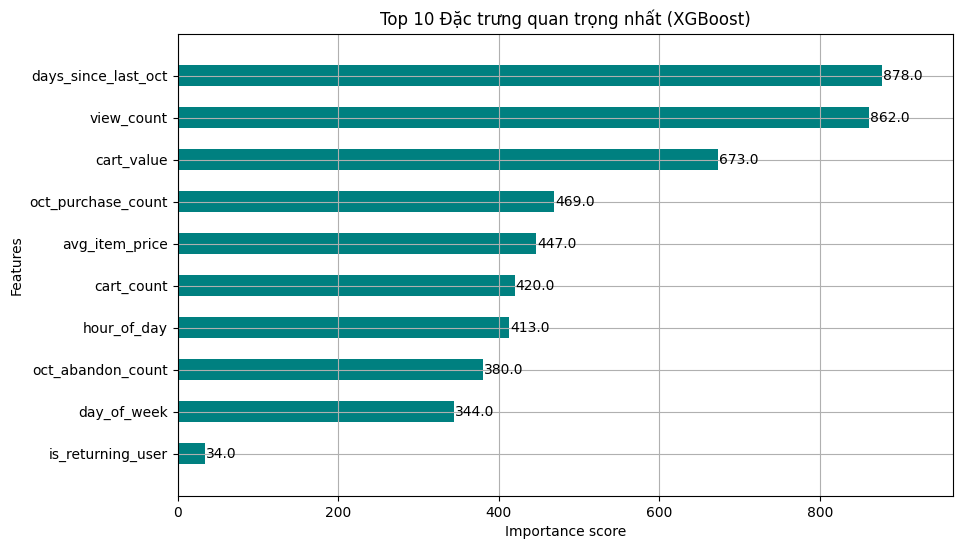

In [5]:
import matplotlib.pyplot as plt
from xgboost import plot_importance

fig, ax = plt.subplots(figsize=(10, 6))
plot_importance(model, max_num_features=10, ax=ax, height=0.5, color='teal', title='Top 10 Đặc trưng quan trọng nhất (XGBoost)')
plt.show()


## 4. Đánh giá Chuyên sâu (Deep Evaluation)
Vẽ biểu đồ PR Curve, Calibration Curve, và Profit ROI Curve.

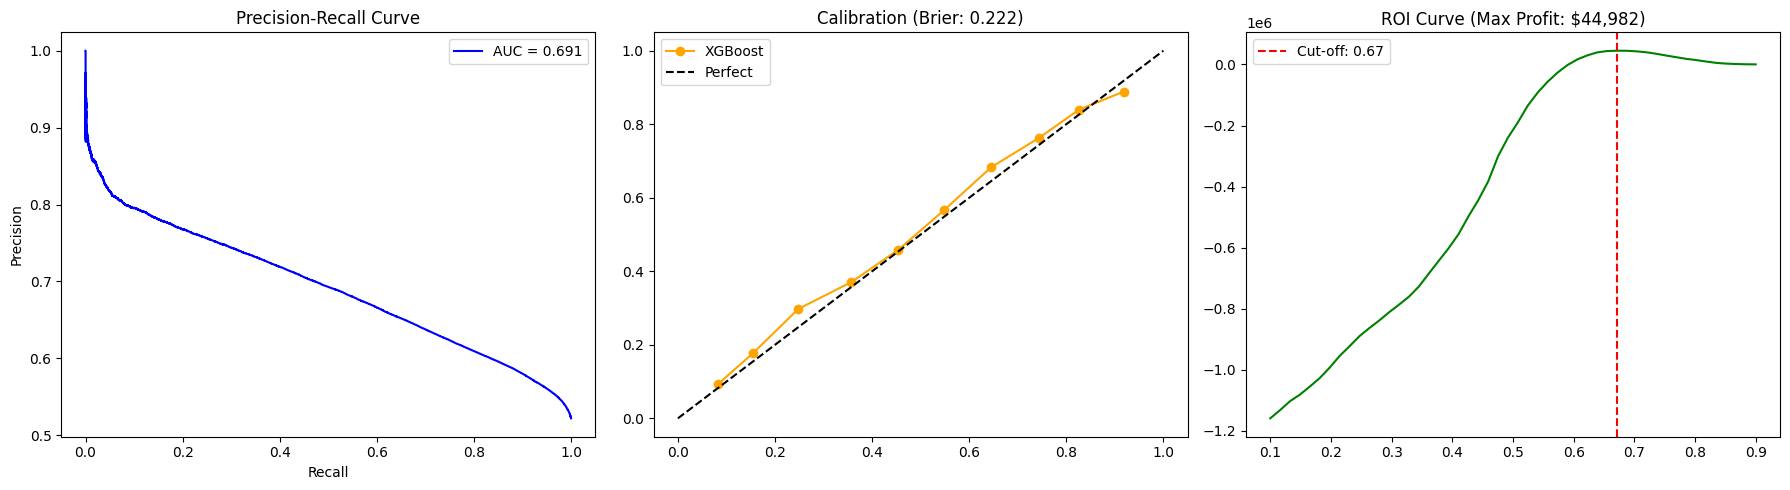

Optimal Threshold: 0.67
Expected Delta Profit on Test Set: $44,982.00


In [6]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, average_precision_score, brier_score_loss, confusion_matrix
from sklearn.calibration import calibration_curve

os.makedirs("../reports/plots", exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. PR Curve
precision, recall, _ = precision_recall_curve(y_test, test_probs)
pr_auc = average_precision_score(y_test, test_probs)
axes[0].plot(recall, precision, color='blue', label=f'AUC = {pr_auc:.3f}')
axes[0].set_title('Precision-Recall Curve')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend()

# 2. Calibration Curve
prob_true, prob_pred = calibration_curve(y_test, test_probs, n_bins=10)
brier = brier_score_loss(y_test, test_probs)
axes[1].plot(prob_pred, prob_true, marker='o', color='orange', label='XGBoost')
axes[1].plot([0,1], [0,1], 'k--', label='Perfect')
axes[1].set_title(f'Calibration (Brier: {brier:.3f})')
axes[1].legend()

# 3. Profit Curve
thresholds = np.linspace(0.1, 0.9, 50)
profits = []
for t in thresholds:
    preds = (test_probs >= t).astype(int)
    tp = np.sum((preds == 1) & (y_test == 1))
    fp = np.sum((preds == 1) & (y_test == 0))
    profits.append((tp * 4) - (fp * 10))

best_idx = np.argmax(profits)
best_thresh = thresholds[best_idx]
best_profit = profits[best_idx]

axes[2].plot(thresholds, profits, color='green')
axes[2].axvline(best_thresh, color='red', linestyle='--', label=f'Cut-off: {best_thresh:.2f}')
axes[2].set_title(f'ROI Curve (Max Profit: ${best_profit:,.0f})')
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"Optimal Threshold: {best_thresh:.2f}")
print(f"Expected Delta Profit on Test Set: ${best_profit:,.2f}")
